In [168]:
district_number = 154
race = f'State House of Representatives - District {district_number}'
#race = 'President of the US'
district_map_file = './gis/house-2023-shape.zip'
previous_file = './data/state_house_2024.csv'

# Template race name

import pandas as pd
import numpy as np

import sos
import colors

current_year = 2026
curr, candidates = sos.import_current(race, year=current_year)
curr = curr.rename(str.upper, level='Precinct')

prev = pd.read_csv(previous_file, index_col=['Race', 'County', 'Precinct']).loc[race]
prev = prev.rename(str.upper, level='Precinct')
prev_is_substitute = (prev['is_sub'] == 1).all()
prev = prev.drop(columns=['is_sub'])
prev

,,Rep,Dem
County,Precinct,,
Baker,BAKER,883,590
Calhoun,CALHOUN,900,1153
Clay,CLAY,663,771
Dougherty,DOUGHERTY,920,6190
Early,EARLY,2718,2158
Miller,MILLER,2045,670
Quitman,QUITMAN,656,480
Randolph,RANDOLPH,1373,1601
Seminole,SEMINOLE,2811,1191


In [169]:
import utils

utils.mk_formatted_timestamp()

'As of Sunday, 01 November 2026 at 12:48 AM Eastern Time'

# Current tally

Below shows the current tally of votes for each candidate as shown on the [Secretary of State's website](https://results.sos.ga.gov/results/public/Georgia). It may or may not be a good reflection of the final result.

In [170]:
summary = pd.DataFrame(curr[candidates].sum().astype(int).sort_values(ascending=False), columns=['Votes'])
summary['Share'] = (summary['Votes'] / summary['Votes'].sum()).fillna(0)
(summary.style
 .format('{:,}', subset=['Votes'])
 .format('{:.2%}', subset=['Share']))

,Votes,Share
Gerald E. Greene (I) (Rep),0,0.00%
Harry James (Dem),0,0.00%


# Map

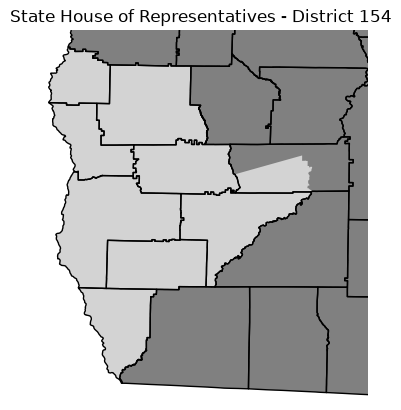

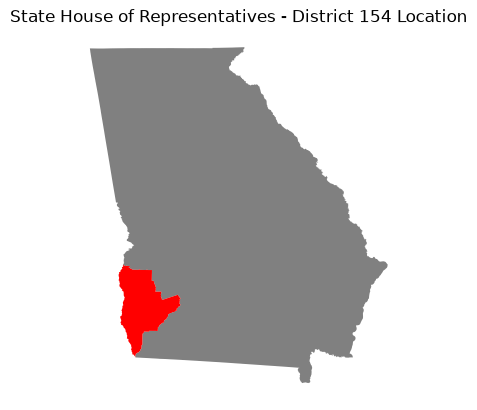

In [171]:
import geopandas
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Counties
counties = utils.import_county_map()

# Precincts
metro_prec_data = geopandas.read_file('./regions/regions_metro.json')
metro_prec_data = metro_prec_data.rename(columns={'index': 'Precinct'})
metro_prec_data = metro_prec_data.sort_index()

metro_prec_data['Precinct'] = metro_prec_data['Precinct'].apply(str.upper)

metro_prec_data = metro_prec_data.set_index(['Election', 'County', 'Precinct'])
metro_prec_data = metro_prec_data.sort_index()

current_metro_precs = metro_prec_data.loc[str(current_year)]
metro_counties = current_metro_precs.index.get_level_values('County').unique()
nonmetro_counties_geo = counties[~counties.index.isin(metro_counties)]
nonmetro_counties_geo.index = pd.MultiIndex.from_tuples([(county, county.upper()) for county in nonmetro_counties_geo.index])
mask = curr.index.intersection(current_metro_precs.index)
county_geometry = nonmetro_counties_geo.geometry.set_crs(current_metro_precs.crs)
geometry = pd.concat([current_metro_precs.geometry[mask], county_geometry])
# TODO: add sanity check to make sure all geometries selected


# Districts
district_map = geopandas.read_file(district_map_file)
district_map = district_map.set_index('DATA')

background_geo = district_map.drop(district_number).dissolve()

def second_max(k: np.ndarray):
    return np.sort(k)[-2]

unit_shares = curr[candidates].div(curr[candidates].sum(axis=1), axis=0).fillna(0) * 100
winners = curr[candidates].idxmax(axis=1)
winners[curr[candidates].max(axis=1) == curr[candidates].apply(second_max, axis=1)] = 'Tie'
winners[curr[candidates].sum(axis=1) == 0] = 'No results'
margins = unit_shares.max(axis=1) - unit_shares.apply(second_max, axis=1)

fig, ax = plt.subplots()
ax.set_title(race)

share_norm = mcolors.Normalize(-10, np.maximum(50, margins.max()))

for cand in candidates:
    party = colors.party_name(cand)

    match party:
        case 'Dem':
            color_scheme = colors.democrats
        case 'Rep':
            color_scheme = colors.republicans
        case _:
            color_scheme = colors.others

    selected = winners[winners == cand]
    if len(selected) == 0:
        continue

    selected = selected[selected.index.intersection(geometry.index)]
    margins_selected = margins[selected.index]

    selected_geos = geopandas.GeoDataFrame(margins_selected, columns=['Margin'], geometry=geometry[selected.index])
    selected_geos.plot('Margin', cmap=color_scheme, ax=ax, norm=share_norm)

if 'No results' in winners.values:
    geometry[winners[winners == 'No results'].index].plot(color='lightgray', ax=ax)
if 'Tie' in winners.values:
    geometry[winners[winners == 'Tie'].index].plot(color='purple', ax=ax)

background_geo.plot(color='gray', ax=ax, autolim=False)
counties.plot(color='None', ax=ax, autolim=False)
ax.set_axis_off()
plt.show()

# Placement map
fig, ax = plt.subplots()
background_geo.plot(color='gray', ax=ax)
district_map.loc[[district_number]].plot(color='red', ax=ax)
ax.set_axis_off()
ax.set_title(f'{race} Location')
plt.show()

# Swingometer

<b>Note</b>: because this race was uncontested during the last cycle, the 2024 presidential election results are used as a benchmark instead.


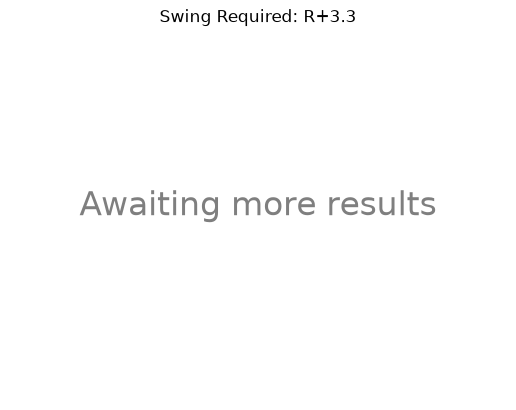

In [ ]:
if prev_is_substitute:
    print('<b>Note</b>: because this race was uncontested during the last cycle, the 2024 presidential election results are used as a benchmark instead.')


import dials

fig, ax = plt.subplots()

bm_table = prev.sum()
bm_table = bm_table / bm_table.sum() * 100
two_party_contest = len(candidates) == 2
swing_req_s = (bm_table['Dem'] - bm_table['Rep']) / 2 if two_party_contest else bm_table.max() - second_max(bm_table)
challenger_party = bm_table.idxmin()
swing_req = (challenger_party, np.abs(swing_req_s))
completed_counties = curr[curr['Reported?']]
benchmark_namer = {colors.party_name(cand): cand for cand in candidates}

ax.set_title(f'Swing Required: {utils.point_formatter(swing_req)}')
ax.set_axis_off()


if len(completed_counties) == 0:
    ax.text(0.5, 0.5, 'Awaiting more results', ha='center', fontsize=24, alpha=0.5)
    measured_swing_s = 0

else:
    share_table = completed_counties[candidates].sum()
    share_table = share_table / share_table.sum() * 100

    filtered_benchmark = prev.loc[completed_counties.index].sum()
    filtered_benchmark = filtered_benchmark / filtered_benchmark.sum() * 100

    measured_swing_s = ((share_table[benchmark_namer['Rep']] - filtered_benchmark['Rep']) 
                        - (share_table[benchmark_namer['Dem']] - filtered_benchmark['Dem'])) / 2 if two_party_contest else \
        share_table[benchmark_namer[challenger_party]] - filtered_benchmark[challenger_party]
    measured_swing = (challenger_party, measured_swing_s)

    dials.dial_from_swing_required(swing_req_s, ax=ax, swing=measured_swing_s, 
                                   pty=None)

    ax.text(0, -0.2, f'Swing Measured: {utils.point_formatter(measured_swing)}', ha='center')

plt.show()
# TODO: Finish this page
# TODO: Do race counter and notifier for range tolerance leavings
# TODO: Adress obfuscation for statewide races
# TODO: US Senate and PSC elections statewide
# TODO: Automate SSH